# Mini-Courier Planner Capstone

This notebook is the complete executable implementation. Run all cells from top to bottom in VS Code. It loads the fictional CSV datasets, prioritizes parcels with merge sort, solves a 0/1 knapsack, builds a weighted graph, runs Dijkstra and nearest-neighbor TSP, checks correctness, benchmarks each component, and writes measured charts and evidence images.

**Capacity:** 18.0 kg. **Knapsack objective:** maximize declared parcel value. Priority sorting is an independent dispatch ranking by priority score (descending), then deadline (ascending).

## Phase 1 - Problem design

A single courier trip starts and ends at `Depot`. Parcels have a destination, weight, priority, deadline, and declared value. The vehicle has a fixed capacity. Roads are undirected and weighted in kilometers. Parcel ranking supports dispatch review; knapsack chooses the highest total declared value that fits; route planning visits the selected parcels' unique destinations. The route uses shortest-path distances in the road graph.

## Phases 2 and 3 - Algorithms

The following cell contains the complete algorithm implementations and runs the sample scenario. No sorting, knapsack, shortest-path, or TSP solver is delegated to a library.

PHASE 1 | input validation
12 parcels; 13 locations; 78 undirected road links; capacity 18.0 kg

PHASE 2 | priority order (top 6)


,parcel_id,destination,priority_score,deadline_hours
0,P006,Hospital,100,1
1,P001,Clinic,98,2
2,P003,University,91,3
3,P009,Museum,88,3
4,P005,Station,84,4
5,P011,Harbor,80,6


Knapsack selected 7 parcels: P001, P003, P006, P009, P010, P011, P012
Packed weight 17.8/18.0 kg; total declared value 2610

PHASE 3 | route results
Graph contains 13 vertices and 78 undirected edges
Tour: Depot -> Clinic -> Hospital -> University -> Museum -> Theatre -> Harbor -> Stadium -> Depot
Total shortest-path travel distance: 30.00 km

CORRECTNESS CHECKS
[PASS] Priority sort order
[PASS] Knapsack capacity
[PASS] Knapsack optimum (exhaustive oracle)
[PASS] Dijkstra shortest path (independent 3-node oracle)
[PASS] Route visits each packed destination once
[PASS] Route starts and ends at depot
[PASS] Route distance recomputation


,algorithm,input_size,scale,time_seconds
0,Merge sort,250,small,0.003514
1,Merge sort,2000,large,0.064367
2,0/1 Knapsack DP,20,small,0.005337
3,0/1 Knapsack DP,80,large,0.022513
4,Dijkstra (single source),30,small,0.000148
5,Dijkstra (single source),120,large,0.001202
6,Nearest-neighbor TSP,10,small,0.000036
7,Nearest-neighbor TSP,40,large,0.000773


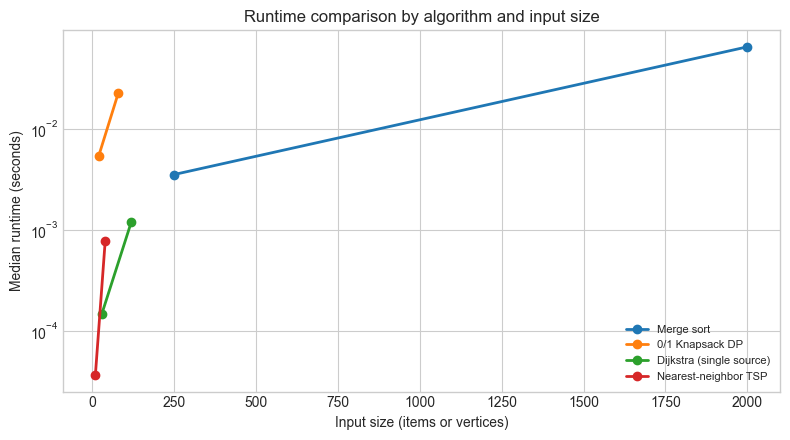

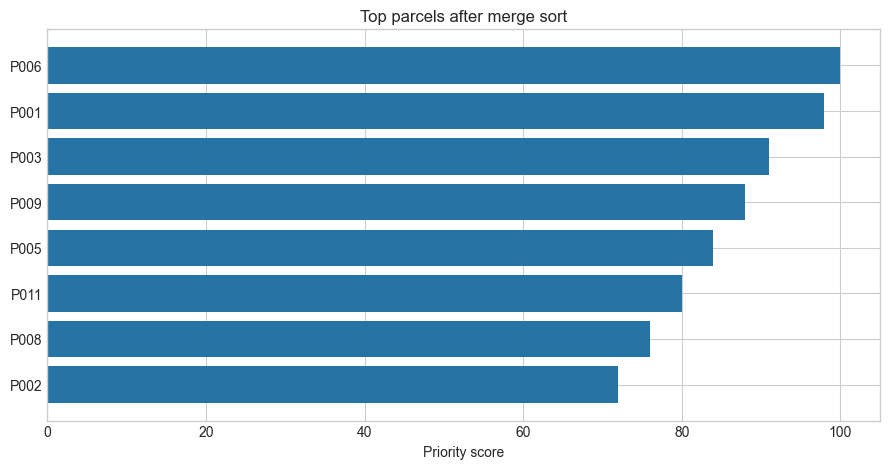

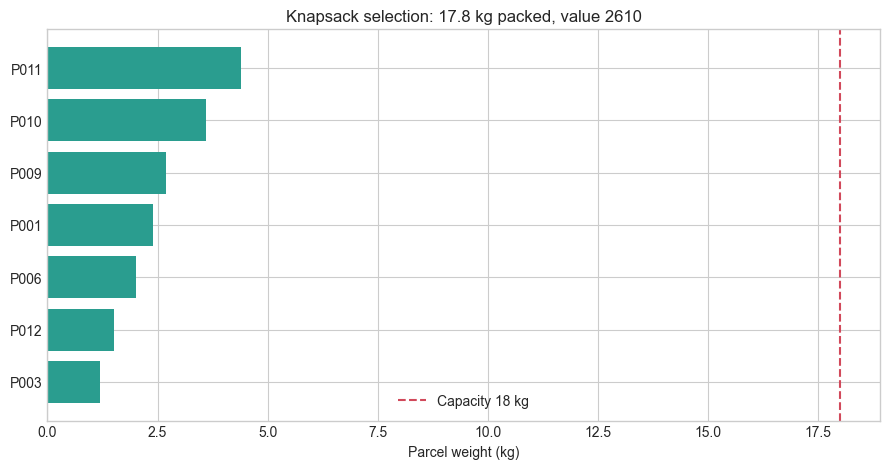

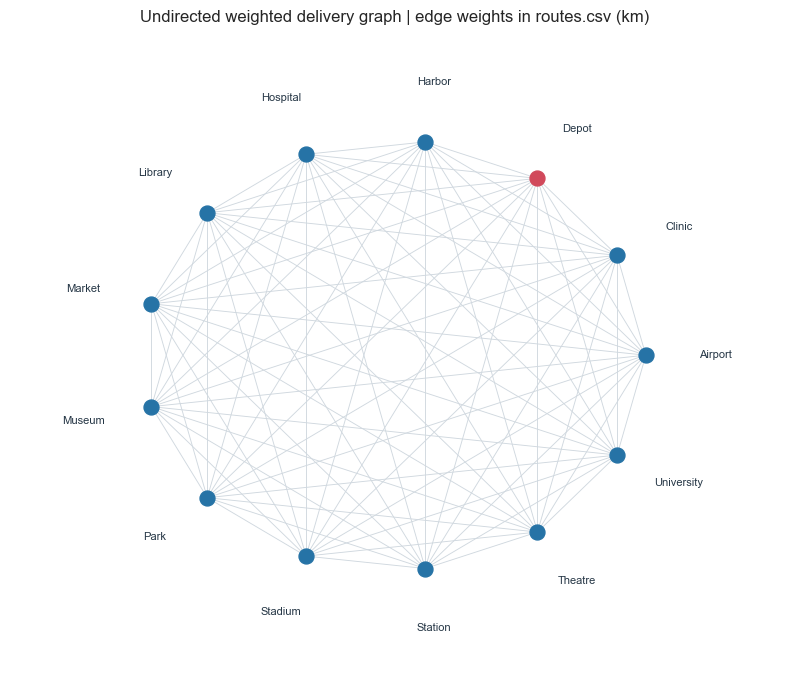

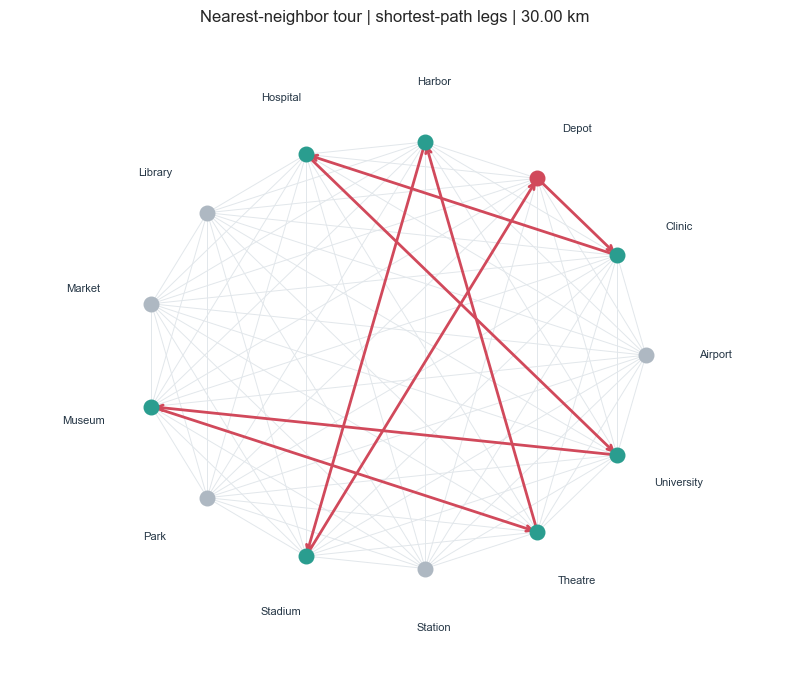

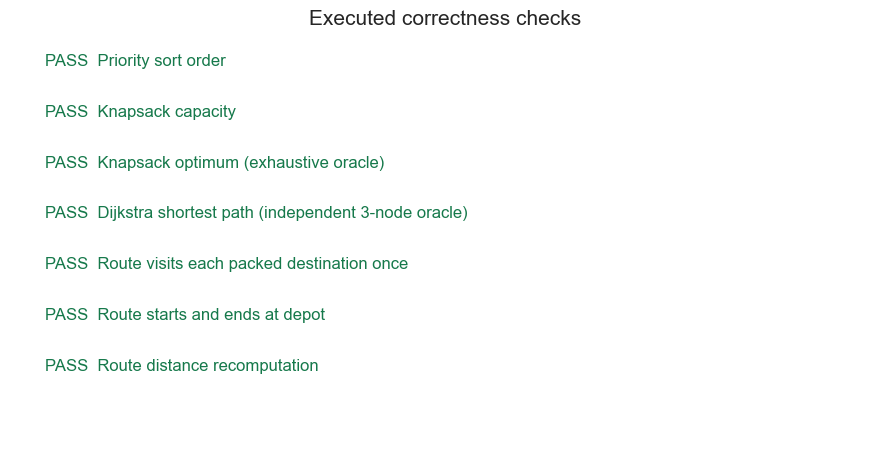

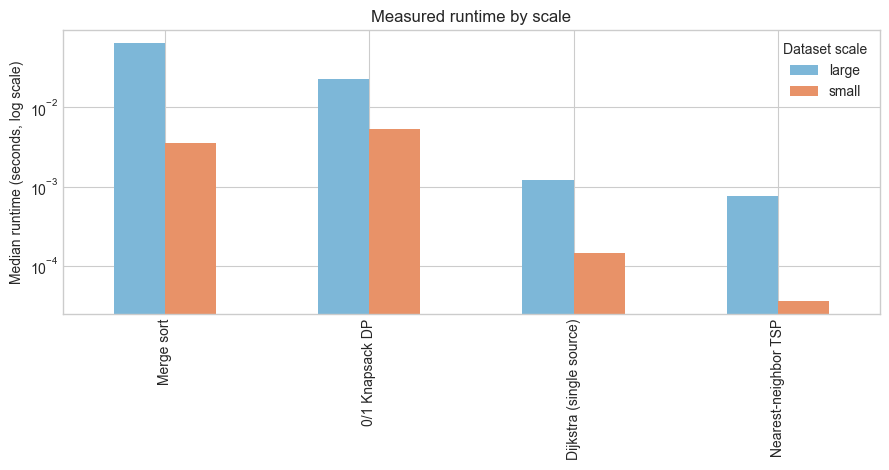


PHASE 5 | complete demonstration
Packed 7 of 12 parcels, then routed 7 selected destinations over 30.00 km.
All 7 correctness checks passed. Benchmark rows: 8. Evidence images written to images/.


In [1]:
from pathlib import Path
import heapq, math, statistics, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd()
if not (ROOT / 'datasets' / 'parcels.csv').exists():
    ROOT = Path(__file__).resolve().parent if '__file__' in globals() else ROOT
IMG = ROOT / 'images'
SHOT = IMG / 'screenshots'
IMG.mkdir(exist_ok=True); SHOT.mkdir(exist_ok=True)

# Phase 1 - data model and problem definition
parcels = pd.read_csv(ROOT / 'datasets' / 'parcels.csv')
route_edges = pd.read_csv(ROOT / 'datasets' / 'routes.csv')
assert parcels.parcel_id.is_unique and not parcels.isna().any().any()
assert route_edges.distance_km.gt(0).all()

# Phase 2 - stable merge sort by priority descending, then deadline ascending
def merge_sort_parcels(items):
    """Return parcels sorted by priority score desc, deadline asc, ID asc; O(n log n)."""
    def key(p): return (-int(p['priority_score']), float(p['deadline_hours']), str(p['parcel_id']))
    def sort(seq):
        if len(seq) <= 1: return seq[:]
        mid=len(seq)//2; left=sort(seq[:mid]); right=sort(seq[mid:]); out=[]; i=j=0
        while i<len(left) and j<len(right):
            if key(left[i]) <= key(right[j]): out.append(left[i]); i+=1
            else: out.append(right[j]); j+=1
        return out+left[i:]+right[j:]
    return sort(list(items))

priority_records = parcels.to_dict('records')
prioritized = merge_sort_parcels(priority_records)
assert prioritized == sorted(priority_records, key=lambda p:(-int(p['priority_score']),float(p['deadline_hours']),str(p['parcel_id'])))

# 0/1 Knapsack: exact integer decagrams (0.1 kg) avoid float capacity errors.
def knapsack_01(items, capacity_units):
    """Maximize declared value under capacity; O(nW) time and O(nW) space."""
    weights=[int(round(float(p['weight_kg'])*10)) for p in items]
    values=[int(p['declared_value']) for p in items]
    n=len(items); dp=[[0]*(capacity_units+1) for _ in range(n+1)]
    for i in range(1,n+1):
        w,v=weights[i-1],values[i-1]
        for cap in range(capacity_units+1):
            dp[i][cap]=dp[i-1][cap]
            if w<=cap: dp[i][cap]=max(dp[i][cap],dp[i-1][cap-w]+v)
    chosen=[]; cap=capacity_units
    for i in range(n,0,-1):
        if dp[i][cap] != dp[i-1][cap]:
            chosen.append(items[i-1]); cap-=weights[i-1]
    chosen.reverse()
    return chosen, dp[n][capacity_units]

CAPACITY_KG=18.0
capacity_units=int(round(CAPACITY_KG*10))
packed, packed_value=knapsack_01(priority_records,capacity_units)
packed_ids={p['parcel_id'] for p in packed}
packed_weight=sum(float(p['weight_kg']) for p in packed)
assert packed_weight <= CAPACITY_KG+1e-9
# Exhaustive subset oracle confirms optimality for this small sample (2^12 subsets).
best=0
for mask in range(1<<len(priority_records)):
    w=sum(int(round(priority_records[i]['weight_kg']*10)) for i in range(len(priority_records)) if mask>>i&1)
    v=sum(int(priority_records[i]['declared_value']) for i in range(len(priority_records)) if mask>>i&1)
    if w<=capacity_units: best=max(best,v)
assert packed_value == best

# Phase 3 - undirected weighted graph and Dijkstra shortest paths
def build_graph(edge_frame):
    graph={}
    for row in edge_frame.to_dict('records'):
        a,b,d=str(row['from_node']),str(row['to_node']),float(row['distance_km'])
        graph.setdefault(a,[]).append((b,d)); graph.setdefault(b,[]).append((a,d))
    for node in graph: graph[node].sort(key=lambda x:x[0])
    return graph

graph=build_graph(route_edges)
def dijkstra(graph, source):
    """Single-source shortest paths with a binary heap; O((V+E) log V)."""
    dist={node:math.inf for node in graph}; prev={node:None for node in graph}
    if source not in graph: raise KeyError(f'Unknown source: {source}')
    dist[source]=0.0; heap=[(0.0,source)]
    while heap:
        d,u=heapq.heappop(heap)
        if d != dist[u]: continue
        for v,w in graph[u]:
            cand=d+w
            if cand < dist[v]-1e-12:
                dist[v]=cand; prev[v]=u; heapq.heappush(heap,(cand,v))
    return dist,prev

def reconstruct_path(prev, source, target):
    if source==target:return [source]
    path=[]; cur=target
    while cur is not None:
        path.append(cur)
        if cur==source: return list(reversed(path))
        cur=prev[cur]
    raise ValueError(f'No path from {source} to {target}')

all_dist={}; all_prev={}
for node in graph: all_dist[node],all_prev[node]=dijkstra(graph,node)
# Independent small graph oracle: direct edges plus the only 2-edge alternative.
check_graph={'A':[('B',4),('C',10)],'B':[('A',4),('C',3)],'C':[('A',10),('B',3)]}
assert dijkstra(check_graph,'A')[0]['C']==7

# Nearest-neighbor TSP approximation over shortest-path distances; returns to depot.
def nearest_neighbor_tour(nodes, distance_map, start='Depot'):
    """Greedy O(k^2) visit order with a return to start; not guaranteed optimal."""
    remaining=set(nodes)-{start}; route=[start]; current=start
    while remaining:
        nxt=min(remaining,key=lambda n:(distance_map[current][n],n))
        route.append(nxt); remaining.remove(nxt); current=nxt
    if route[-1] != start: route.append(start)
    length=sum(distance_map[a][b] for a,b in zip(route,route[1:]))
    return route,length

deliveries=sorted({p['destination'] for p in packed})
route,route_km=nearest_neighbor_tour(deliveries,all_dist,'Depot')
assert route[0]=='Depot' and route[-1]=='Depot'
assert set(route[1:-1])==set(deliveries) and len(route)==len(deliveries)+2
assert abs(route_km-sum(all_dist[a][b] for a,b in zip(route,route[1:])))<1e-10

print('PHASE 1 | input validation')
print(f'{len(parcels)} parcels; {len(graph)} locations; {len(route_edges)} undirected road links; capacity {CAPACITY_KG:.1f} kg')
print('\nPHASE 2 | priority order (top 6)')
priority_df=pd.DataFrame(prioritized)[['parcel_id','destination','priority_score','deadline_hours']]
display(priority_df.head(6))
print(f'Knapsack selected {len(packed)} parcels: {", ".join(p["parcel_id"] for p in packed)}')
print(f'Packed weight {packed_weight:.1f}/{CAPACITY_KG:.1f} kg; total declared value {packed_value}')
print('\nPHASE 3 | route results')
print(f'Graph contains {len(graph)} vertices and {sum(map(len,graph.values()))//2} undirected edges')
print(f'Tour: {" -> ".join(route)}')
print(f'Total shortest-path travel distance: {route_km:.2f} km')

# Phase 4 - reproducible correctness checks and benchmark runs
checks={
 'Priority sort order': prioritized==sorted(priority_records,key=lambda p:(-int(p['priority_score']),float(p['deadline_hours']),str(p['parcel_id']))),
 'Knapsack capacity': packed_weight<=CAPACITY_KG+1e-9,
 'Knapsack optimum (exhaustive oracle)': packed_value==best,
 'Dijkstra shortest path (independent 3-node oracle)': dijkstra(check_graph,'A')[0]['C']==7,
 'Route visits each packed destination once': set(route[1:-1])==set(deliveries) and len(route)==len(deliveries)+2,
 'Route starts and ends at depot': route[0]=='Depot' and route[-1]=='Depot',
 'Route distance recomputation': abs(route_km-sum(all_dist[a][b] for a,b in zip(route,route[1:])))<1e-10,
}
assert all(checks.values()), checks
print('\nCORRECTNESS CHECKS')
for name,ok in checks.items(): print(f'[{"PASS" if ok else "FAIL"}] {name}')

def timed_median(fn,repeats=5):
    samples=[]
    for _ in range(repeats):
        t0=time.perf_counter_ns(); fn(); samples.append((time.perf_counter_ns()-t0)/1e9)
    return statistics.median(samples)

def random_parcels(n,seed=11):
    rng=np.random.default_rng(seed)
    return [{'parcel_id':f'B{i:05d}','priority_score':int(rng.integers(1,101)),
             'deadline_hours':float(rng.integers(1,49)),'weight_kg':float(rng.integers(1,51))/10,
             'declared_value':int(rng.integers(50,1001))} for i in range(n)]

def random_connected_graph(n,seed=11):
    rng=np.random.default_rng(seed); g={f'N{i}':[] for i in range(n)}
    # Chain guarantees connectivity; extra random undirected links make it sparse.
    edges=set((i,i+1) for i in range(n-1))
    for i in range(n):
        for j in range(i+2,n):
            if rng.random()<min(0.06,8/max(n,1)): edges.add((i,j))
    for i,j in edges:
        w=float(rng.integers(10,1000))/100
        g[f'N{i}'].append((f'N{j}',w));g[f'N{j}'].append((f'N{i}',w))
    return g

bench=[]
for label,n in [('small',250),('large',2000)]:
    sample=random_parcels(n)
    bench.append({'algorithm':'Merge sort','input_size':n,'scale':label,'time_seconds':timed_median(lambda s=sample:merge_sort_parcels(s),3)})
for label,n in [('small',20),('large',80)]:
    sample=random_parcels(n)
    bench.append({'algorithm':'0/1 Knapsack DP','input_size':n,'scale':label,'time_seconds':timed_median(lambda s=sample:knapsack_01(s,300),3)})
for label,n in [('small',30),('large',120)]:
    g=random_connected_graph(n)
    bench.append({'algorithm':'Dijkstra (single source)','input_size':n,'scale':label,'time_seconds':timed_median(lambda gg=g:dijkstra(gg,'N0'),5)})
for label,n in [('small',10),('large',40)]:
    names=[f'N{i}' for i in range(n+1)]; g=random_connected_graph(n+1)
    dm={node:dijkstra(g,node)[0] for node in names}
    bench.append({'algorithm':'Nearest-neighbor TSP','input_size':n,'scale':label,'time_seconds':timed_median(lambda nn=names[1:],dd=dm:nearest_neighbor_tour(nn,dd,'N0'),5)})
runtime_df=pd.DataFrame(bench,columns=['algorithm','input_size','scale','time_seconds'])
assert not runtime_df.isna().any().any() and runtime_df.time_seconds.gt(0).all()
runtime_df.to_csv(IMG/'runtime_measurements.csv',index=False,float_format='%.9f')
runtime_df.to_csv(ROOT/'runtime_measurements.csv',index=False,float_format='%.9f')
display(runtime_df)

# Phase 5 - plots/evidence are generated from the actual outputs above.
plt.style.use('seaborn-v0_8-whitegrid')
fig,ax=plt.subplots(figsize=(8,4.5))
for algorithm,group in runtime_df.groupby('algorithm',sort=False):
    group=group.sort_values('input_size'); ax.plot(group.input_size,group.time_seconds,marker='o',linewidth=2,label=algorithm)
ax.set(title='Runtime comparison by algorithm and input size',xlabel='Input size (items or vertices)',ylabel='Median runtime (seconds)')
ax.set_yscale('log');ax.legend(fontsize=8);fig.tight_layout();fig.savefig(IMG/'runtime_comparison.png',dpi=180);plt.show();plt.close(fig)

# Parcel priority evidence
fig,ax=plt.subplots(figsize=(9,4.8)); top=pd.DataFrame(prioritized).head(8).iloc[::-1]
ax.barh(top.parcel_id,top.priority_score,color='#2673a6');ax.set(xlabel='Priority score',title='Top parcels after merge sort');fig.tight_layout();fig.savefig(SHOT/'parcel_prioritization.png',dpi=160);plt.show();plt.close(fig)
# Packing evidence
fig,ax=plt.subplots(figsize=(9,4.8)); p_df=pd.DataFrame(packed).sort_values('weight_kg')
ax.barh(p_df.parcel_id,p_df.weight_kg,color='#2a9d8f');ax.axvline(CAPACITY_KG,color='#d1495b',linestyle='--',label=f'Capacity {CAPACITY_KG:g} kg')
ax.set(xlabel='Parcel weight (kg)',title=f'Knapsack selection: {packed_weight:.1f} kg packed, value {packed_value}');ax.legend();fig.tight_layout();fig.savefig(SHOT/'packing_plan.png',dpi=160);plt.show();plt.close(fig)
# Graph evidence with readable external node labels
nodes=sorted(graph); angles=np.linspace(0,2*np.pi,len(nodes),endpoint=False);pos={node:(0.86*np.cos(a),0.86*np.sin(a)) for node,a in zip(nodes,angles)}
fig,ax=plt.subplots(figsize=(8,7))
for a in nodes:
    for b,w in graph[a]:
        if a<b:
            x1,y1=pos[a];x2,y2=pos[b];ax.plot([x1,x2],[y1,y2],color='#d0d8df',linewidth=.65,zorder=1)
for node,(x,y) in pos.items():
    ax.scatter(x,y,s=115,color=('#d1495b' if node=='Depot' else '#2673a6'),zorder=3)
    dx,dy=x/0.86*1.10,y/0.86*1.10
    ax.text(dx,dy,node,ha='center',va='center',fontsize=8,color='#263746',zorder=4)
ax.set_title('Undirected weighted delivery graph | edge weights in routes.csv (km)')
ax.set_xlim(-1.32,1.32);ax.set_ylim(-1.30,1.30);ax.axis('off');fig.tight_layout();fig.savefig(SHOT/'weighted_graph.png',dpi=160);plt.show();plt.close(fig)
# Route evidence using the delivery node graph coordinates in sequence
fig,ax=plt.subplots(figsize=(8,7));
for a in nodes:
    for b,w in graph[a]:
        if a<b:
            x1,y1=pos[a];x2,y2=pos[b];ax.plot([x1,x2],[y1,y2],color='#e2e7eb',linewidth=.7,zorder=1)
for a,b in zip(route,route[1:]):
    x1,y1=pos[a];x2,y2=pos[b];ax.annotate('',xy=(x2,y2),xytext=(x1,y1),arrowprops=dict(arrowstyle='->',color='#d1495b',lw=2),zorder=2)
for node,(x,y) in pos.items():
    ax.scatter(x,y,s=110,color=('#d1495b' if node=='Depot' else ('#2a9d8f' if node in deliveries else '#aeb8c2')),zorder=3)
    dx,dy=x/0.86*1.10,y/0.86*1.10;ax.text(dx,dy,node,ha='center',va='center',fontsize=8,color='#263746',zorder=4)
ax.set_title(f'Nearest-neighbor tour | shortest-path legs | {route_km:.2f} km');ax.set_xlim(-1.32,1.32);ax.set_ylim(-1.30,1.30);ax.axis('off');fig.tight_layout();fig.savefig(SHOT/'delivery_route.png',dpi=160);plt.show();plt.close(fig)
# Correctness evidence
fig,ax=plt.subplots(figsize=(9,4.6)); ax.axis('off')
for i,(name,ok) in enumerate(checks.items()):ax.text(.04,.92-i*.125,('PASS  ' if ok else 'FAIL  ')+name,fontsize=12,color=('#16794b' if ok else '#bb2d3b'),transform=ax.transAxes)
ax.set_title('Executed correctness checks',fontsize=15);fig.tight_layout();fig.savefig(SHOT/'correctness_checks.png',dpi=160);plt.show();plt.close(fig)
# Performance evidence from benchmark table
fig,ax=plt.subplots(figsize=(9,4.8));piv=runtime_df.pivot(index='algorithm',columns='scale',values='time_seconds').reindex(['Merge sort','0/1 Knapsack DP','Dijkstra (single source)','Nearest-neighbor TSP'])
piv.plot(kind='bar',ax=ax,color=['#7db7d8','#e89268']);ax.set_yscale('log');ax.set_ylabel('Median runtime (seconds, log scale)');ax.set_xlabel('');ax.set_title('Measured runtime by scale');ax.legend(title='Dataset scale');fig.tight_layout();fig.savefig(SHOT/'performance_results.png',dpi=160);plt.show();plt.close(fig)

# A notebook output evidence panel brings key results together.
print('\nPHASE 5 | complete demonstration')
print(f'Packed {len(packed)} of {len(parcels)} parcels, then routed {len(deliveries)} selected destinations over {route_km:.2f} km.')
print(f'All {len(checks)} correctness checks passed. Benchmark rows: {len(runtime_df)}. Evidence images written to images/.')


## Phase 4 - Correctness and runtime

Assertions check ordering, capacity, optimality against an exhaustive subset oracle, Dijkstra against an independent small graph, route coverage, depot return, and route-distance recomputation. The benchmark records median wall-clock runtime over repeated runs at small and large scales. Timings vary by machine and Python version; the CSV and chart are regenerated from the current execution.

Complexities: merge sort O(n log n) time and O(n) auxiliary space; 0/1 knapsack O(nW) time and O(nW) space for n parcels and integer capacity W; heap-based Dijkstra O((V+E) log V) time and O(V+E) space; nearest-neighbor TSP O(k²) selection time and O(k) route storage for k stops (excluding the shortest-path preprocessing).

## Phase 5 - Demonstration and evidence

The cell saves the measured runtime chart and CSV, plus PNG evidence for parcel sorting, packing, the weighted graph, the final route, correctness checks, and performance results. These are generated from the actual program output, not captured from a local IDE. See `PROJECT_REPORT.md` for the experimental results and observations.